<a href="https://colab.research.google.com/github/uditchoudhary2109/MP3-UDIT/blob/main/MP3codes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Determine the nth root of complex number and represent in cartesian and polar form
import numpy as np

a = float(input("Enter the real part: "))
b = float(input("Enter the imaginary part: "))

z = complex(a, b)

n = int(input("Enter the value of n: "))

if n <= 0:
    print("Enter a positive integer for n.")

else:
    r = abs(z)
    theta = np.angle(z)

    print("\nPolar form of the complex number:")
    print("Modulus =", r)
    print("Argument =", theta, "radians")


    print("\nThe", n, "roots are:\n")

    for k in range(n):
        root_r = r ** (1/n)
        root_theta = (theta + 2 * np.pi * k) / n

        x = root_r * np.cos(root_theta)
        y = root_r * np.sin(root_theta)

        print("Root", k+1)
        print("Cartesian Form: {:.4f} + ({:.4f})i".format(x, y))

        print("Polar Form: {:.4f} (cos({:.4f}) + i sin({:.4f}))".format(
            root_r, root_theta, root_theta))

        print()


Enter the real part: 3
Enter the imaginary part: 2
Enter the value of n: 4

Polar form of the complex number:
Modulus = 3.605551275463989
Argument = 0.5880026035475675 radians

The 4 roots are:

Root 1
Cartesian Form: 1.3631 + (0.2018)i
Polar Form: 1.3780 (cos(0.1470) + i sin(0.1470))

Root 2
Cartesian Form: -0.2018 + (1.3631)i
Polar Form: 1.3780 (cos(1.7178) + i sin(1.7178))

Root 3
Cartesian Form: -1.3631 + (-0.2018)i
Polar Form: 1.3780 (cos(3.2886) + i sin(3.2886))

Root 4
Cartesian Form: 0.2018 + (-1.3631)i
Polar Form: 1.3780 (cos(4.8594) + i sin(4.8594))



In [2]:
#Transformation of complex numbers as 2-D vectors e.g. translation, scaling, rotation,reflection.
import numpy as np
x = float(input("Enter real part (x): "))
y = float(input("Enter imaginary part (y): "))

z = complex(x, y)

print("\nOriginal Complex Number:", z)

tx = float(input("\nEnter translation along x-axis: "))
ty = float(input("Enter translation along y-axis: "))

translation = z + complex(tx, ty)

print("\nAfter Translation:", translation)

sx = float(input("\nEnter scaling factor along x-axis: "))
sy = float(input("Enter scaling factor along y-axis: "))

scaling = complex(x * sx, y * sy)

print("\nAfter Scaling:", scaling)

angle = float(input("\nEnter rotation angle in degrees: "))

theta = np.radians(angle)

rotation = z * complex(np.cos(theta), np.sin(theta))

print("\nAfter Rotation:", rotation)

print("\nReflection Options:")
print("1. Reflection about X-axis")
print("2. Reflection about Y-axis")
print("3. Reflection about Origin")
print("4. Reflection about Line y = x")

choice = int(input("Enter your choice: "))

if choice == 1:
    reflection = complex(x, -y)

elif choice == 2:
    reflection = complex(-x, y)

elif choice == 3:
    reflection = complex(-x, -y)

elif choice == 4:
    reflection = complex(y, x)

else:
    reflection = z
    print("Invalid choice!")

print("After Reflection:", reflection)


Enter real part (x): 2
Enter imaginary part (y): 3

Original Complex Number: (2+3j)

Enter translation along x-axis: 2
Enter translation along y-axis: 3

After Translation: (4+6j)

Enter scaling factor along x-axis: 5
Enter scaling factor along y-axis: 6

After Scaling: (10+18j)

Enter rotation angle in degrees: 60

After Rotation: (-1.5980762113533158+3.2320508075688776j)

Reflection Options:
1. Reflection about X-axis
2. Reflection about Y-axis
3. Reflection about Origin
4. Reflection about Line y = x
Enter your choice: 3
After Reflection: (-2-3j)


In [3]:
#Solving a definite integral by Gauss Legendre quadrature method. Application – representation of a function as a linear combination of Legendre polynomials.

import numpy as np
def f(x):
    return x**2 + 2*x + 1

a = float(input("Enter lower limit: "))
b = float(input("Enter upper limit: "))

n = int(input("Enter number of points: "))

x, w = np.polynomial.legendre.leggauss(n)

t = (b-a)/2 * x + (a+b)/2

I = (b-a)/2 * np.sum(w * f(t))

print("\nGauss-Legendre Integral =", I)

from numpy.polynomial import Polynomial

p = Polynomial([1, 2, 1])
exact = p.integ()(b) - p.integ()(a)

print("Exact Integral =", exact)



Enter lower limit: 0
Enter upper limit: 5
Enter number of points: 100

Gauss-Legendre Integral = 71.66666666666663
Exact Integral = 71.66666666666666


In [4]:
#Solving improper integrals over entire real axis or the positive real axis using Gauss Lagaurre and Gauss Hermite quadrature method. Comparison of results with the ones obtained by contour integration analytically.
import numpy as np

def f(x):
    return 1 / (1 + x)**2

n = int(input("Enter number of points: "))

x, w = np.polynomial.laguerre.laggauss(n)
I = np.sum(w * np.exp(x) * f(x))

exact = 1.0

print("\nGauss-Laguerre Result =", I)
print("Analytical Result =", exact)
print("Absolute Error =", abs(I - exact))


Enter number of points: 100

Gauss-Laguerre Result = 0.9974263004565057
Analytical Result = 1.0
Absolute Error = 0.00257369954349429


In [7]:
#Comparison of convergence of improper integral computed by Newton Cotes and Gauss Quadrature Methods.
import numpy as np

def f(t):
    return np.exp(-t/(1-t)) / (1-t)**2

exact = 1.0

def simpson(a, b, n):
    if n % 2 != 0:
        n += 1

    h = (b-a)/n
    x = np.linspace(a, b, n+1)
    y = f(x)

    I = h/3 * (y[0] + y[-1]
        + 4*np.sum(y[1:-1:2])
        + 2*np.sum(y[2:-1:2]))

    return I

def gauss(a, b, n):
    x, w = np.polynomial.legendre.leggauss(n)

    t = (b-a)/2*x + (a+b)/2

    I = (b-a)/2 * np.sum(w*f(t))

    return I

print("Convergence Comparison")
print("-----------------------------------------------")
print(" N       Simpson       Gauss       Simpson Error       Gauss Error")

for n in [4, 8, 16, 32, 64]:

    I1 = simpson(0, 1, n)
    I2 = gauss(0, 1, n)

    error1 = abs(exact-I1)
    error2 = abs(exact-I2)

    print(n, "  ", round(I1, 8), "  ",
          round(I2, 8), "  ",
          round(error1, 8), "  ",
          round(error2, 8))


Convergence Comparison
-----------------------------------------------
 N       Simpson       Gauss       Simpson Error       Gauss Error
4    nan    1.02348224    nan    0.02348224
8    nan    1.00079579    nan    0.00079579
16    nan    0.99999561    nan    4.39e-06
32    nan    1.0    nan    0.0
64    nan    1.0    nan    0.0


/tmp/ipykernel_642/1185594989.py:5: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-t/(1-t)) / (1-t)**2
/tmp/ipykernel_642/1185594989.py:5: RuntimeWarning: invalid value encountered in divide
  return np.exp(-t/(1-t)) / (1-t)**2


In [9]:
#Computation of Discrete Fourier Transform (DFT) using complex numbers.
import numpy as np

N = int(input("Enter the number of elements: "))

x = []

for i in range(N):
    a = complex(input("Enter element: "))
    x.append(a)

x = np.array(x, dtype=complex)

X = np.fft.fft(x)

print("\nDiscrete Fourier Transform (DFT):")

for k in range(N):
    print("X[{}] = {:.4f} + ({:.4f})i".format(
        k, X[k].real, X[k].imag))

x_reconstructed = np.fft.ifft(X)

print("\nInverse DFT (Original Sequence):")
print(np.round(x_reconstructed, 4))


Enter the number of elements: 3
Enter element: 1
Enter element: 2
Enter element: 5

Discrete Fourier Transform (DFT):
X[0] = 8.0000 + (0.0000)i
X[1] = -2.5000 + (2.5981)i
X[2] = -2.5000 + (-2.5981)i

Inverse DFT (Original Sequence):
[1.+0.j 2.+0.j 5.+0.j]


FFT of the function exp(-x^2):

Frequency: -6.35  FFT: 0j
Frequency: -6.2508  FFT: (-1.7763568394002505e-15+8.071321389024888e-14j)
Frequency: -6.1516  FFT: (-8.881784197001252e-15+1.6092682741941644e-13j)
Frequency: -6.0523  FFT: (-1.687538997430238e-14+2.4197310821705287e-13j)
Frequency: -5.9531  FFT: (-3.241851231905457e-14+3.232969447708456e-13j)
Frequency: -5.8539  FFT: (-4.984901380566953e-14+4.046346591124461e-13j)
Frequency: -5.7547  FFT: (-7.133182933216631e-14+4.862360514223951e-13j)
Frequency: -5.6555  FFT: (-9.965639424791561e-14+5.686250081904376e-13j)
Frequency: -5.5563  FFT: (-1.2826545381372512e-13+6.507129904353981e-13j)
Frequency: -5.457  FFT: (-1.6510230682609262e-13+7.334272078551862e-13j)
Frequency: -5.3578  FFT: (-2.0444063109081867e-13+8.167841403228238e-13j)
Frequency: -5.2586  FFT: (-2.4934915243690625e-13+9.005643453185996e-13j)
Frequency: -5.1594  FFT: (-2.9956592761948286e-13+9.85656001262214e-13j)
Frequency: -5.0602  FFT: (-3.527733660746435e-13+1.070130095

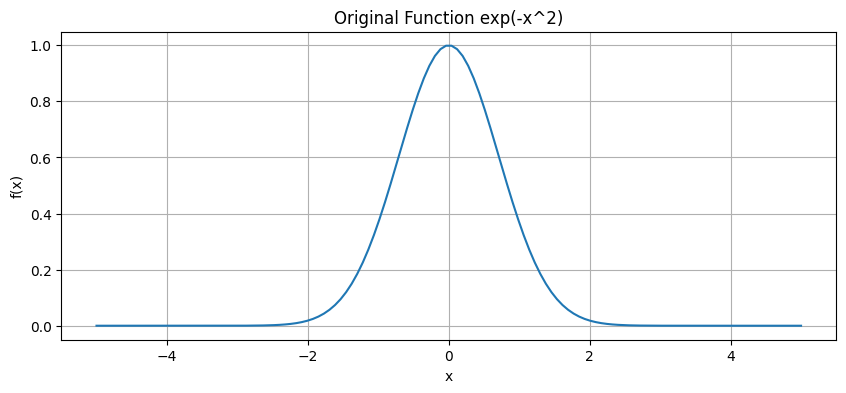

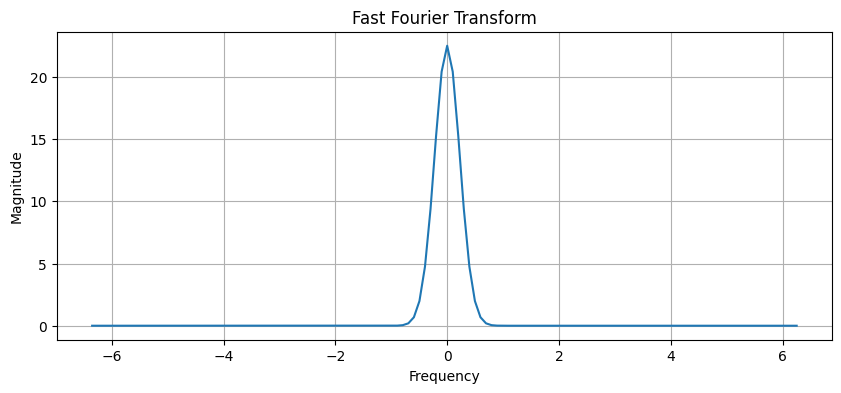

In [10]:
#Fast Fourier Transform of given function in tabulated or mathematical form e.g function ecp(-x2).
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return np.exp(-x**2)
N = 128
x = np.linspace(-5, 5, N)

y = f(x)

Y = np.fft.fft(y)

dx = x[1] - x[0]
freq = np.fft.fftfreq(N, d=dx)

Y_shifted = np.fft.fftshift(Y)
freq_shifted = np.fft.fftshift(freq)

print("FFT of the function exp(-x^2):\n")

for i in range(N):
    print("Frequency:", round(freq_shifted[i], 4),
          " FFT:", Y_shifted[i])

plt.figure(figsize=(10, 4))
plt.plot(x, y)
plt.title("Original Function exp(-x^2)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid()
plt.show()
plt.figure(figsize=(10, 4))
plt.plot(freq_shifted, np.abs(Y_shifted))
plt.title("Fast Fourier Transform")
plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.grid()
plt.show()


Enter length of bar: 1
Enter temperature at left end: 20
Enter temperature at right end: 200
Enter number of divisions: 1000

Equilibrium Temperature Distribution
-----------------------------------
x = 0.0  Temperature = 20.0
x = 0.001  Temperature = 20.18
x = 0.002  Temperature = 20.36
x = 0.003  Temperature = 20.54
x = 0.004  Temperature = 20.72
x = 0.005  Temperature = 20.9
x = 0.006  Temperature = 21.08
x = 0.007  Temperature = 21.26
x = 0.008  Temperature = 21.44
x = 0.009  Temperature = 21.62
x = 0.01  Temperature = 21.8
x = 0.011  Temperature = 21.98
x = 0.012  Temperature = 22.16
x = 0.013  Temperature = 22.34
x = 0.014  Temperature = 22.52
x = 0.015  Temperature = 22.7
x = 0.016  Temperature = 22.88
x = 0.017  Temperature = 23.06
x = 0.018  Temperature = 23.24
x = 0.019  Temperature = 23.42
x = 0.02  Temperature = 23.6
x = 0.021  Temperature = 23.78
x = 0.022  Temperature = 23.96
x = 0.023  Temperature = 24.14
x = 0.024  Temperature = 24.32
x = 0.025  Temperature = 24.5
x = 0

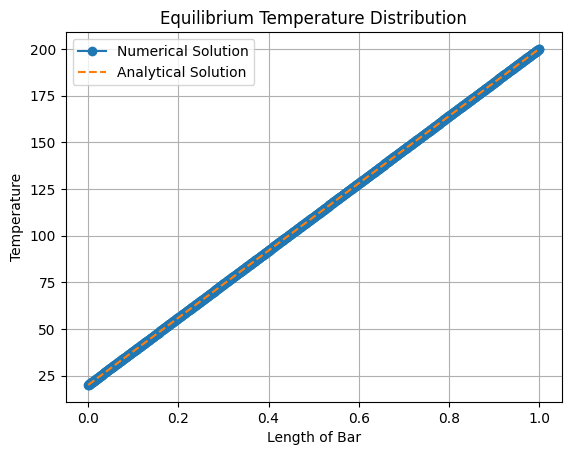

In [11]:
#The equilibrium temperature of a bar of length L with insulated horizontal sides and the ends maintained at fixed temperatures.
import numpy as np
import matplotlib.pyplot as plt

L = float(input("Enter length of bar: "))
T1 = float(input("Enter temperature at left end: "))
T2 = float(input("Enter temperature at right end: "))
N = int(input("Enter number of divisions: "))

x = np.linspace(0, L, N+1)
h = L/N

T = np.zeros(N+1)

T[0] = T1
T[N] = T2

A = np.zeros((N-1, N-1))
b = np.zeros(N-1)

for i in range(N-1):
    A[i, i] = -2

    if i > 0:
        A[i, i-1] = 1

    if i < N-2:
        A[i, i+1] = 1
b[0] = -T1
b[-1] = -T2

T[1:N] = np.linalg.solve(A, b)

print("\nEquilibrium Temperature Distribution")
print("-----------------------------------")

for i in range(N+1):
    print("x =", round(x[i], 4),
          " Temperature =", round(T[i], 4))


T_exact = T1 + (T2-T1)*x/L

print("\nAnalytical Temperature:")
print(np.round(T_exact, 4))

plt.plot(x, T, 'o-', label="Numerical Solution")
plt.plot(x, T_exact, '--', label="Analytical Solution")

plt.xlabel("Length of Bar")
plt.ylabel("Temperature")
plt.title("Equilibrium Temperature Distribution")
plt.legend()
plt.grid()
plt.show()



Concentration Profile
---------------------
x = 0.0  y(x) = 1.0
x = 0.1  y(x) = 0.930947
x = 0.2  y(x) = 0.871204
x = 0.3  y(x) = 0.820173
x = 0.4  y(x) = 0.777343
x = 0.5  y(x) = 0.742287
x = 0.6  y(x) = 0.714654
x = 0.7  y(x) = 0.694167
x = 0.8  y(x) = 0.680622
x = 0.9  y(x) = 0.673883
x = 1.0  y(x) = 0.673883

Analytical Solution:
[1.       0.928718 0.86673  0.813418 0.768246 0.730763 0.700594 0.677436
 0.661059 0.651297 0.648054]


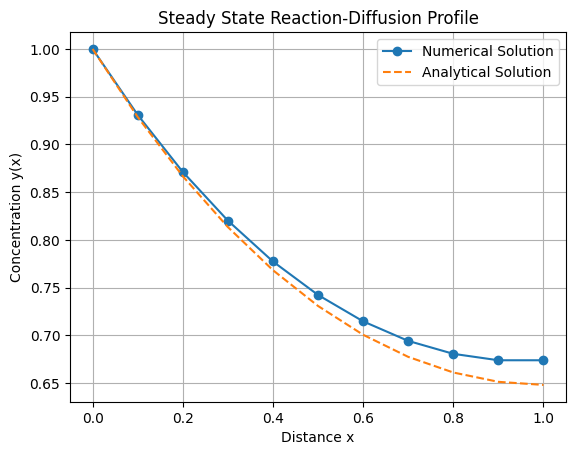

In [12]:
#Solve for the steady state concentration profile y(x) in the reaction-diffusion problem given by 𝑦′′(𝑥) − 𝑦(𝑥) = 0 with 𝑦(0) = 1, 𝑦′(1) = 0.
import numpy as np
import matplotlib.pyplot as plt
a = 0
b = 1

N = 10
h = (b-a)/N

x = np.linspace(a, b, N+1)
A = np.zeros((N, N))
B = np.zeros(N)

for i in range(N-1):
    A[i, i] = -2 - h**2
    A[i, i+1] = 1
    if i > 0:
        A[i, i-1] = 1

B[0] = -1
A[N-1, N-2] = -1
A[N-1, N-1] = 1
B[N-1] = 0


y = np.zeros(N+1)
y[0] = 1
y[1:] = np.linalg.solve(A, B)

y_exact = np.cosh(1-x) / np.cosh(1)

print("Concentration Profile")
print("---------------------")

for i in range(N+1):
    print("x =", round(x[i], 4),
          " y(x) =", round(y[i], 6))

print("\nAnalytical Solution:")
print(np.round(y_exact, 6))

plt.plot(x, y, 'o-', label="Numerical Solution")
plt.plot(x, y_exact, '--', label="Analytical Solution")

plt.xlabel("Distance x")
plt.ylabel("Concentration y(x)")
plt.title("Steady State Reaction-Diffusion Profile")
plt.legend()
plt.grid()
plt.show()



Temperature Distribution:
[[ 75.   100.   100.   100.   100.   100.   100.   100.   100.   100.
  100.   100.   100.   100.   100.   100.   100.   100.   100.    50.  ]
 [ 75.    87.12  91.68  93.64  94.54  94.97  95.15  95.18  95.12  94.98
   94.76  94.46  94.04  93.45  92.58  91.2   88.86  84.43  74.77  50.  ]
 [ 75.    81.8   85.98  88.32  89.57  90.2   90.45  90.46  90.31  90.03
   89.61  89.04  88.26  87.19  85.65  83.36  79.82  74.09  64.66  50.  ]
 [ 75.    79.08  82.12  84.08  85.22  85.79  85.98  85.91  85.64  85.21
   84.61  83.82  82.78  81.39  79.48  76.79  72.95  67.45  59.77  50.  ]
 [ 75.    77.41  79.35  80.67  81.44  81.77  81.78  81.55  81.13  80.55
   79.8   78.86  77.66  76.11  74.07  71.36  67.75  62.99  56.97  50.  ]
 [ 75.    76.21  77.18  77.81  78.09  78.08  77.82  77.38  76.78  76.06
   75.19  74.15  72.88  71.31  69.35  66.85  63.69  59.78  55.13  50.  ]
 [ 75.    75.24  75.36  75.3   75.05  74.62  74.04  73.36  72.58  71.71
   70.75  69.66  68.4   66.93  65.

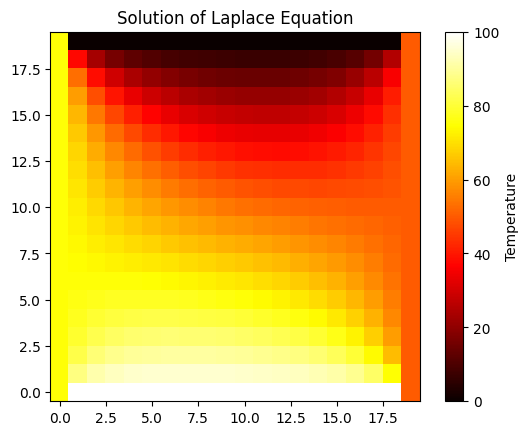

In [13]:
#Use any numerical method to solve Laplace equation/ wave equation/ Heat Equation.

import numpy as np
import matplotlib.pyplot as plt

N = 20

u = np.zeros((N, N))

u[0, :] = 100
u[-1, :] = 0
u[:, 0] = 75
u[:, -1] = 50

for k in range(1000):
    old = u.copy()

    for i in range(1, N-1):
        for j in range(1, N-1):
            u[i, j] = 0.25 * (
                old[i+1, j] + old[i-1, j] +
                old[i, j+1] + old[i, j-1]
            )

print("Temperature Distribution:")
print(np.round(u, 2))

plt.imshow(u, cmap='hot', origin='lower')
plt.colorbar(label="Temperature")
plt.title("Solution of Laplace Equation")
plt.show()
